# Phase 6A — Feature availability and ablation study

Development-only nested sensitivity study: original HGB and LR, four prespecified subsets, no class weighting/resampling, fixed .50 reference threshold. Source latest merged main `11b6638`. No final model/policy choice, held-out evaluation or Phase 6B.

## Google Colab setup

Use a fresh runtime. Upload this notebook plus `preprocessing.py`, `02_cleaned_dataset.csv`, `03_split_indices.json`, `06_nested_cv_targeting.ipynb`, `06_nested_cv_targeting_summary.md`, `07_threshold_decision_summary.md` and `08_imbalance_treatment_summary.md` to the same folder. Optionally upload `dataset.csv` for byte-hash verification and `tests/test_preprocessing.py` under `tests/` for the existing unit tests. Alternatively mount Drive and set PROJECT_DIR in the next cell. Tested with sklearn 1.8.0, pandas 2.2.3, NumPy 2.3.5. If needed use a separate setup cell `%pip install scikit-learn==1.8.0 pandas==2.2.3 numpy==2.3.5 matplotlib threadpoolctl` then restart runtime. Imbalanced-learn is not needed in this phase.

Run all in order. This executes 1,940 fresh model fits with sequential search and bounded native threads; allow several minutes or longer depending on hardware. Only the new summary is written by notebook code; save the executed notebook to preserve outputs. Existing artifacts are not overwritten. All paths use PROJECT_DIR; no local scratch dependency is required. A live hosted Colab session was not available for verification.

## 1. Exact source and development rows

Validate the cleaned-file hash before saved positions, restore their order, parse development rows only. Reuse exact outer-fold position checksum from Phase 5A. Archived parameter grids/results are used to verify provenance/full-feature replication, not to skip reduced-feature searches or select parameters from outer labels.


In [1]:
from pathlib import Path
import sys,json,hashlib,warnings,time
import numpy as np
import pandas as pd
pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_rows", 150)
import matplotlib.pyplot as plt
import sklearn
from sklearn.base import BaseEstimator,TransformerMixin,clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GridSearchCV,ParameterGrid
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,average_precision_score,roc_curve,precision_recall_curve
from threadpoolctl import threadpool_limits
from IPython.display import display
PROJECT_DIR=Path.cwd()  # mounted Drive folder also supported
required=['02_cleaned_dataset.csv','03_split_indices.json','preprocessing.py','06_nested_cv_targeting_summary.md','06_nested_cv_targeting.ipynb','07_threshold_decision_summary.md','08_imbalance_treatment_summary.md']
if any(not (PROJECT_DIR/n).is_file() for n in required):
    try:
        from google.colab import files
    except ImportError as exc:
        raise FileNotFoundError('Place required files in PROJECT_DIR') from exc
    files.upload()
if any(not (PROJECT_DIR/n).is_file() for n in required):raise FileNotFoundError(required)
sys.path.insert(0,str(PROJECT_DIR))
from preprocessing import make_preprocessor,make_cv,FEATURES,CATEGORICAL,NUMERICAL,RECENCY
BASE_MAIN_COMMIT='11b6638'

def sha(p):return hashlib.sha256(p.read_bytes()).hexdigest()
input_hashes={n:sha(PROJECT_DIR/n) for n in required}
for optional in ['dataset.csv','03_preprocessing_summary.md','04_baseline_summary.md','05_model_comparison_summary.md','05_model_comparison.ipynb','05b_hist_gradient_boosting.ipynb']:
    if (PROJECT_DIR/optional).is_file():input_hashes[optional]=sha(PROJECT_DIR/optional)
saved=json.loads((PROJECT_DIR/'03_split_indices.json').read_text())
assert input_hashes['02_cleaned_dataset.csv']==saved['input_sha256'] and saved['row_count']==41176
idx=np.asarray(saved['development_indices'],dtype=int);held=np.asarray(saved['held_out_indices'],dtype=int)
assert len(idx)==32940 and len(held)==8236 and len(np.unique(idx))==len(idx) and len(np.unique(held))==len(held)
assert not np.intersect1d(idx,held).size
np.testing.assert_array_equal(np.sort(np.r_[idx,held]),np.arange(41176))
keep=set(idx.tolist())
dev=pd.read_csv(PROJECT_DIR/'02_cleaned_dataset.csv',float_precision='round_trip',skiprows=lambda line:line>0 and line-1 not in keep)
assert dev.shape==(32940,16) and dev.columns.tolist()==FEATURES+['y']
dev.index=np.sort(idx);dev=dev.loc[idx].copy();snapshot=dev.copy(deep=True)
assert not dev.isna().any().any() and dev.y.isin([0,1]).all()
assert np.isfinite(dev[NUMERICAL+RECENCY].to_numpy()).all()
assert dev.recency_available.isin([0,1]).all() and dev.recency_days.between(0,27).all()
assert dev.loc[dev.recency_available.eq(0),'recency_days'].eq(0).all()
X=dev[FEATURES].copy();y=dev.y.copy();DEV_KEY=frozenset(X.index)
outer_folds=list(make_cv().split(X,y))
for (a,b),(aa,bb) in zip(outer_folds,make_cv().split(X,y)):
    np.testing.assert_array_equal(a,aa);np.testing.assert_array_equal(b,bb)
coverage=np.zeros(len(X),int)
for a,b in outer_folds:
    assert len(a)==26352 and len(b)==6588 and not np.intersect1d(a,b).size
    assert not set(idx[a]).intersection(held) and not set(idx[b]).intersection(held)
    coverage[b]+=1
assert (coverage==1).all()
outer_hash=hashlib.sha256(b''.join(idx[b].astype('<i8').tobytes() for _,b in outer_folds)).hexdigest()
assert outer_hash=='6016ca88c4c344724075ade804828d47f03a69bf7337f5287cee0f4a444457c4'
print('Latest-main source baseline:',BASE_MAIN_COMMIT,'| saved development rows:',len(X),'| outer fold hash:',outer_hash)
print('Held-out features/labels never parsed; no new train-test assignment.')


# These source summaries/notebooks are provenance, not training data.
import ast
prior_nb=json.loads((PROJECT_DIR/'06_nested_cv_targeting.ipynb').read_text())
prior_code='\n'.join(''.join(c['source']) for c in prior_nb['cells'] if c['cell_type']=='code')
prior_ast=ast.parse(prior_code)
prior_grids=ast.literal_eval(next(n.value for n in prior_ast.body if isinstance(n,ast.Assign) and any(isinstance(t,ast.Name) and t.id=='GRIDS' for t in n.targets)))
prior_text=(PROJECT_DIR/'06_nested_cv_targeting_summary.md').read_text()
def prior_table(heading):
    lines=[]
    for line in prior_text.split(heading,1)[1].splitlines():
        if line.startswith('| '):lines.append(line)
        elif lines:break
    assert len(lines)>2
    cols=[a.strip() for a in lines[0].split('|')[1:-1]]
    return pd.DataFrame([[a.strip() for a in l.split('|')[1:-1]] for l in lines[2:]],columns=cols)
prior_scores=prior_table('## Individual outer-fold predictive results')
prior_params=prior_table('## Fold-specific selected hyperparameters')


Latest-main source baseline: 11b6638 | saved development rows: 32940 | outer fold hash: 6016ca88c4c344724075ade804828d47f03a69bf7337f5287cee0f4a444457c4
Held-out features/labels never parsed; no new train-test assignment.


## 2. Prespecified subsets and approved preprocessing adapter

Full (15), No Economic Indicators (10), No Previous Campaign History (12), Customer Attributes Only (7). The table gives exact input and transformer order. All retained predictors stay Provisional.

The existing factory accepts model families, not subsets. This notebook-only adapter filters column lists in a fresh unfitted factory and removes empty components. It preserves OHE/scalers and entirely removes recency when excluded; no constants substitute for removed features. Full adapter equivalence is tested against original output, names and learned statistics using only a small outer-training fixture. Unseen-category handling and cloneability are also checked.

Each complete estimator owns fresh preprocessing, a stateless representation guard and classifier. Fit/prediction audits enforce authorized row sets, exact input schema, training-only categories/scaler statistics and fixed validation-time parameters. LR keeps available-only conditional recency scaling when present; HGB remains unscaled with numeric one-hot indicators. No global matrix or predictive model is fitted in technical fixtures.


In [2]:
MODELS=['HistGradientBoosting','LogisticRegression']
ECONOMIC=['emp.var.rate','cons.price.idx','cons.conf.idx','euribor3m','nr.employed']
HISTORY=['previous','recency_available','recency_days']
GROUPS={
 'Full':list(FEATURES),
 'No Economic Indicators':[c for c in FEATURES if c not in ECONOMIC],
 'No Previous Campaign History':[c for c in FEATURES if c not in HISTORY],
 'Customer Attributes Only':[c for c in FEATURES if c not in ECONOMIC+HISTORY]}
assert list(map(len,GROUPS.values()))==[15,10,12,7]
assert GROUPS['Customer Attributes Only']==['age','job','marital','education','default','housing','loan']
METRICS=['AP','ROC_AUC','Accuracy','Precision','Recall','F1']
GRIDS={m:prior_grids[m] for m in MODELS}
assert GRIDS=={
 'LogisticRegression':{'classifier__C':[.1,1.,10.]},
 'HistGradientBoosting':{'classifier__learning_rate':[.05,.1],'classifier__max_iter':[100,200],
 'classifier__max_leaf_nodes':[15,31],'classifier__l2_regularization':[0.,1.]}}
feature_table=pd.DataFrame([{'feature_group':g,'n_predictors':len(cols),'ordered_input_columns':', '.join(cols),
 'categorical_columns':', '.join(c for c in CATEGORICAL if c in cols),
 'quantitative_columns':', '.join(c for c in NUMERICAL if c in cols),
 'recency_transformer_columns':', '.join(RECENCY) if all(c in cols for c in RECENCY) else 'REMOVED'} for g,cols in GROUPS.items()])
display(feature_table)

def subset_preprocessor(model,group):
    name='logistic_regression' if model=='LogisticRegression' else 'decision_tree'
    p=make_preprocessor(name);ct=p.named_steps['preprocessor'];chosen=GROUPS[group]
    assert not hasattr(ct,'transformers_')
    filtered=[]
    for name,transformer,cols in ct.transformers:
        selected=[c for c in cols if c in chosen]
        if name=='recency':assert selected in [[],RECENCY]
        if selected:filtered.append((name,transformer,selected))
    ct.set_params(transformers=filtered)
    assert set(c for _,_,cols in filtered for c in cols)==set(chosen)
    if not any(c in chosen for c in HISTORY):assert 'recency' not in [t[0] for t in filtered]
    return p

def scores(actual,prob):
    pred=(prob>=.5).astype(int)
    return dict(AP=average_precision_score(actual,prob),ROC_AUC=roc_auc_score(actual,prob),
        Accuracy=accuracy_score(actual,pred),Precision=precision_score(actual,pred,zero_division=0),
        Recall=recall_score(actual,pred,zero_division=0),F1=f1_score(actual,pred,zero_division=0))

class FiniteGuard(TransformerMixin,BaseEstimator):
    def __init__(self,group='Full',scaled=False):self.group=group;self.scaled=scaled
    def check(self,z):
        assert isinstance(z,np.ndarray) and z.ndim==2 and np.isfinite(z).all()
        cols=GROUPS[self.group];tail=len([c for c in NUMERICAL if c in cols])+(2 if 'recency_days' in cols else 0)
        assert np.isin(z[:,:-tail],[0.,1.]).all()
        if 'recency_days' in cols:
            assert np.isin(z[:,-1],[0.,1.]).all() and (z[z[:,-1]==0,-2]==0).all()
            if not self.scaled:assert ((z[:,-2]>=0)&(z[:,-2]<=27)).all()
        return z
    def fit(self,z,y=None):self.check(z);self.n_features_in_=z.shape[1];return self
    def transform(self,z):self.check(z);assert z.shape[1]==self.n_features_in_;return z
    def get_feature_names_out(self,input_features=None):return np.asarray(input_features,dtype=object)

def signature(pre):
    ct=pre.named_steps['preprocessor'];enc=ct.named_transformers_['categorical'];num=ct.named_transformers_['numerical']
    sig={'categories':[a.tolist() for a in enc.categories_],'output_names':pre.get_feature_names_out().tolist()}
    if hasattr(num,'mean_'):sig['numerical']=[num.mean_.tolist(),num.var_.tolist(),num.scale_.tolist(),np.asarray(num.n_samples_seen_).tolist()]
    rec=ct.named_transformers_.get('recency')
    if hasattr(rec,'mean_'):sig['recency']=[rec.mean_,rec.var_,rec.scale_,rec.n_available_]
    return sig

CONTEXT={};FIT_AUDIT=[];PRED_AUDIT=[];WARNING_LOG=[]
class AuditedPipeline(Pipeline):
    def fit(self,X,y=None,**params):
        key=frozenset(X.index);model=CONTEXT['model'];group=CONTEXT['group'];cols=GROUPS[group]
        assert X.columns.tolist()==cols and key!=DEV_KEY and not key.intersection(held)
        assert key in CONTEXT['inner_train_keys'] or key==CONTEXT['outer_train_key']
        assert not key.intersection(CONTEXT['outer_val_key']) and np.array_equal(X.index,y.index)
        pre=self.named_steps['preprocessing'];assert not hasattr(pre.named_steps['preprocessor'],'transformers_')
        with warnings.catch_warnings(record=True) as caught,threadpool_limits(limits=1):
            warnings.simplefilter('always');result=super().fit(X,y,**params)
        ct=pre.named_steps['preprocessor'];enc=ct.named_transformers_['categorical']
        cats=[c for c in CATEGORICAL if c in cols];nums=[c for c in NUMERICAL if c in cols]
        assert set(c for name,t,cs in ct.transformers if name!='remainder' for c in cs)==set(cols)
        assert ct.remainder=='drop'
        for c,levels in zip(cats,enc.categories_):np.testing.assert_array_equal(levels,np.sort(X[c].unique()))
        assert enc.drop is None and enc.handle_unknown=='ignore' and enc.sparse_output is False
        num=ct.named_transformers_['numerical'];rec=ct.named_transformers_.get('recency')
        if model=='LogisticRegression':
            np.testing.assert_allclose(num.mean_,X[nums].mean(),rtol=1e-12,atol=1e-12)
            np.testing.assert_allclose(num.var_,X[nums].var(ddof=0),rtol=1e-12,atol=1e-12)
            sd=np.sqrt(X[nums].var(ddof=0).to_numpy());sd[sd==0]=1
            np.testing.assert_allclose(num.scale_,sd,rtol=1e-12,atol=1e-12)
            assert np.all(np.asarray(num.n_samples_seen_)==len(X))
            if 'recency_days' in cols:
                observed=X.loc[X.recency_available.eq(1),'recency_days'].to_numpy()
                mean=observed.mean() if len(observed) else 0.;var=observed.var(ddof=0) if len(observed) else 0.;sd=np.sqrt(var) if var>0 else 1.
                assert rec.n_available_==len(observed)
                np.testing.assert_allclose([rec.mean_,rec.var_,rec.scale_],[mean,var,sd],rtol=1e-12)
        else:assert not hasattr(num,'mean_') and not hasattr(rec,'mean_')
        if 'recency_days' not in cols:
            assert rec is None and 'recency' not in [t[0] for t in ct.transformers_]
            assert not any('recency' in str(c) for c in pre.get_feature_names_out())
        clf=self.named_steps['classifier'];np.testing.assert_array_equal(clf.classes_,[0,1])
        assert clf.class_weight is None and clf.random_state==42
        if hasattr(clf,'coef_'):assert np.isfinite(clf.coef_).all() and np.isfinite(clf.intercept_).all()
        if model=='HistGradientBoosting':
            assert clf.categorical_features is None and not clf.early_stopping and clf.n_iter_==clf.max_iter
            assert clf.is_categorical_ is None or not np.any(clf.is_categorical_)
        self._fit_rows=key
        role='outer-training refit' if key==CONTEXT['outer_train_key'] else 'inner-training fit'
        for w in caught:WARNING_LOG.append({'outer_fold':CONTEXT['outer_fold'],'model':model,'feature_group':group,'role':role,'category':w.category.__name__,'message':str(w.message)})
        FIT_AUDIT.append({'outer_fold':CONTEXT['outer_fold'],'model':model,'feature_group':group,'role':role,'rows':len(X),
            'input_columns':len(cols),'output_columns':len(pre.get_feature_names_out()),
            'recency_component':('included' if rec is not None else 'removed'),
            'recency_mean':float(rec.mean_) if hasattr(rec,'mean_') else 'not scaled / absent',
            'recency_scale':float(rec.scale_) if hasattr(rec,'scale_') else 'not scaled / absent',
            'warnings':len(caught),'status':'PASS'})
        return result
    def predict_proba(self,X,**params):
        key=frozenset(X.index);group=CONTEXT['group'];cols=GROUPS[group]
        assert X.columns.tolist()==cols and not key.intersection(self._fit_rows) and not key.intersection(held)
        if CONTEXT['prediction_role']=='inner validation':assert key in CONTEXT['inner_val_keys'] and not key.intersection(CONTEXT['outer_val_key'])
        else:assert CONTEXT['prediction_role']=='outer validation' and key==CONTEXT['outer_val_key']
        pre=self.named_steps['preprocessing'];before=signature(pre);z=pre.transform(X);self.named_steps['finite_guard'].transform(z)
        ct=pre.named_steps['preprocessor'];rec=ct.named_transformers_.get('recency')
        nums=[c for c in NUMERICAL if c in cols];n=len(nums)
        if CONTEXT['model']=='LogisticRegression':
            actual_numeric=z[:,-n-2:-2] if rec is not None else z[:,-n:]
            scaler=ct.named_transformers_['numerical']
            np.testing.assert_allclose(actual_numeric,(X[nums].to_numpy()-scaler.mean_)/scaler.scale_)
        else:
            selected=nums+(RECENCY if rec is not None else [])
            np.testing.assert_array_equal(z[:,-len(selected):],X[selected].to_numpy())
        if rec is not None:
            np.testing.assert_array_equal(z[:,-1],X.recency_available)
            assert (z[X.recency_available.eq(0).to_numpy(),-2]==0).all()
            if hasattr(rec,'mean_'):
                mask=X.recency_available.eq(1).to_numpy()
                np.testing.assert_allclose(z[mask,-2],(X.loc[mask,'recency_days']-rec.mean_)/rec.scale_)
        with threadpool_limits(limits=1):out=super().predict_proba(X,**params)
        assert signature(pre)==before and np.isfinite(out).all() and ((out>=0)&(out<=1)).all()
        assert out.shape==(len(X),2)
        PRED_AUDIT.append({'model':CONTEXT['model'],'feature_group':group,'outer_fold':CONTEXT['outer_fold'],
            'role':CONTEXT['prediction_role'],'rows':len(X),'status':'PASS'})
        return out

def factory(model,group):
    clf=LogisticRegression(C=1.,solver='lbfgs',max_iter=1000,random_state=42,class_weight=None) if model=='LogisticRegression' else HistGradientBoostingClassifier(
        learning_rate=.1,max_iter=100,max_leaf_nodes=31,l2_regularization=0.,early_stopping=False,categorical_features=None,class_weight=None,random_state=42)
    return AuditedPipeline([('preprocessing',subset_preprocessor(model,group)),
        ('finite_guard',FiniteGuard(group=group,scaled=model=='LogisticRegression')),('classifier',clf)])

# Technical adapter checks use ONLY a small subset of outer fold 1 training rows, not all development.
technical_rows=outer_folds[0][0];fit_fixture=X.iloc[technical_rows[:300]];val_fixture=X.iloc[technical_rows[300:400]].copy()
val_fixture.iloc[0,val_fixture.columns.get_loc('job')]='__synthetic_unseen__'
adapter_checks=[]
for m in MODELS:
    with threadpool_limits(limits=1):
        original=make_preprocessor('logistic_regression' if m=='LogisticRegression' else 'decision_tree').fit(fit_fixture)
        adapted=subset_preprocessor(m,'Full').fit(fit_fixture)
        np.testing.assert_array_equal(original.get_feature_names_out(),adapted.get_feature_names_out())
        np.testing.assert_array_equal(original.transform(val_fixture),adapted.transform(val_fixture))
        assert signature(original)==signature(adapted)
    for g,cols in GROUPS.items():
        clone(factory(m,g));p=subset_preprocessor(m,g);assert not hasattr(p.named_steps['preprocessor'],'transformers_')
        p.fit(fit_fixture[cols]);before=signature(p);z=p.transform(val_fixture[cols]);assert signature(p)==before
        guard=FiniteGuard(group=g,scaled=m=='LogisticRegression').fit(p.transform(fit_fixture[cols]));guard.transform(z)
        names=p.get_feature_names_out();assert z.shape[1]==len(names)
        jobcols=[i for i,name in enumerate(names) if name.startswith('categorical__job_')]
        assert z[0,jobcols].sum()==0
        if g in ['No Previous Campaign History','Customer Attributes Only']:
            assert 'recency' not in p.named_steps['preprocessor'].named_transformers_
        adapter_checks.append({'model':m,'feature_group':g,'fixture_fit_rows':300,'fixture_transform_rows':100,
            'output_columns':z.shape[1],'full_equivalence':g=='Full','status':'PASS'})
    # The factory still creates the approved unchanged full specification.
    assert [list(cs) for _,_,cs in make_preprocessor('logistic_regression' if m=='LogisticRegression' else 'decision_tree').named_steps['preprocessor'].transformers]==[CATEGORICAL,NUMERICAL,RECENCY]
def inner_score(est,data,actual):
    assert CONTEXT['prediction_role']=='inner validation' and np.array_equal(data.index,actual.index)
    prob=est.predict_proba(data)[:,list(est.classes_).index(1)]
    return {'AP':average_precision_score(actual,prob)}
print('Adapter equivalence/unseen-category/recency-removal/clone checks passed on training-only fixtures.')
print('Full fresh grids for every feature set: 1,900 candidate-fold fits + 40 outer-training refits = 1,940 fits.')
display(pd.DataFrame(adapter_checks))



Adapter equivalence/unseen-category/recency-removal/clone checks passed on training-only fixtures.
Full fresh grids for every feature set: 1,900 candidate-fold fits + 40 outer-training refits = 1,940 fits.


feature_group,n_predictors,ordered_input_columns,categorical_columns,quantitative_columns,recency_transformer_columns
Full,15,"age, job, marital, education, default, housing, loan, previous, emp.var.rate, cons.price.idx, cons.conf.idx, euribor3m, nr.employed, recency_available, recency_days","job, marital, education, default, housing, loan","age, previous, emp.var.rate, cons.price.idx, cons.conf.idx, euribor3m, nr.employed","recency_days, recency_available"
No Economic Indicators,10,"age, job, marital, education, default, housing, loan, previous, recency_available, recency_days","job, marital, education, default, housing, loan","age, previous","recency_days, recency_available"
No Previous Campaign History,12,"age, job, marital, education, default, housing, loan, emp.var.rate, cons.price.idx, cons.conf.idx, euribor3m, nr.employed","job, marital, education, default, housing, loan","age, emp.var.rate, cons.price.idx, cons.conf.idx, euribor3m, nr.employed",REMOVED
Customer Attributes Only,7,"age, job, marital, education, default, housing, loan","job, marital, education, default, housing, loan",age,REMOVED


,model,feature_group,fixture_fit_rows,fixture_transform_rows,output_columns,full_equivalence,status
0,HistGradientBoosting,Full,300,100,40,True,PASS
1,HistGradientBoosting,No Economic Indicators,300,100,35,False,PASS
2,HistGradientBoosting,No Previous Campaign History,300,100,37,False,PASS
3,HistGradientBoosting,Customer Attributes Only,300,100,32,False,PASS
4,LogisticRegression,Full,300,100,40,True,PASS
5,LogisticRegression,No Economic Indicators,300,100,35,False,PASS
6,LogisticRegression,No Previous Campaign History,300,100,37,False,PASS
7,LogisticRegression,Customer Attributes Only,300,100,32,False,PASS


## 3. Nested experiments and .50 reference metrics

Same five outer and five inner StratifiedKFold partitions (shuffle=True, random_state=42) for all eight procedures. Fresh GridSearchCV per feature set within each outer training set, using exact Phase 5A grids and AP refit. No feature set borrows full-feature selected parameters. Threshold is .50 throughout, with no threshold tuning.

All 1,900 inner candidate-fold fits and 40 outer refits are audited. Only frozen inner-selected winners predict outer validation. Full-feature results/parameters must reproduce Phase 5A. Report each fold, mean/sample SD and matched full-minus-subset AP/ROC losses. Inner selection scores are not independent performance. This is development sensitivity after prior exploration, not final model-family validation.


In [3]:
started_all=time.perf_counter();outer_rows=[];selection_rows=[];cost_rows=[];candidate_rows=[];inner_manifest=[]
oof={(m,g):{'prob':np.full(len(X),np.nan),'coverage':np.zeros(len(X),int)} for m in MODELS for g in GROUPS}
for outer_fold,(otr,ova) in enumerate(outer_folds,start=1):
    train_y=y.iloc[otr];inner_folds=list(make_cv().split(X.iloc[otr],train_y))
    for (a,b),(aa,bb) in zip(inner_folds,make_cv().split(X.iloc[otr],train_y)):
        np.testing.assert_array_equal(a,aa);np.testing.assert_array_equal(b,bb)
    for i,(a,b) in enumerate(inner_folds,start=1):
        inner_manifest.append({'outer_fold':outer_fold,'inner_fold':i,'fit_rows':len(a),'validation_rows':len(b),
            'validation_row_sha256':hashlib.sha256(idx[otr[b]].astype('<i8').tobytes()).hexdigest()})
    for model in MODELS:
        for group,cols in GROUPS.items():
            train_X=X.iloc[otr][cols];val_X=X.iloc[ova][cols]
            CONTEXT.update(model=model,group=group,outer_fold=outer_fold,outer_train_key=frozenset(train_X.index),outer_val_key=frozenset(val_X.index),
                inner_train_keys={frozenset(train_X.iloc[a].index) for a,b in inner_folds},inner_val_keys={frozenset(train_X.iloc[b].index) for a,b in inner_folds},
                prediction_role='inner validation')
            before=len(FIT_AUDIT);before_pred=len(PRED_AUDIT);t=time.perf_counter()
            search=GridSearchCV(factory(model,group),GRIDS[model],scoring=inner_score,refit='AP',cv=inner_folds,
                n_jobs=1,error_score='raise',return_train_score=False)
            search.fit(train_X,train_y)
            search_seconds=time.perf_counter()-t;n=len(ParameterGrid(GRIDS[model]))
            assert len(FIT_AUDIT)-before==5*n+1 and len(PRED_AUDIT)-before_pred==5*n
            for i,params in enumerate(search.cv_results_['params']):
                values=np.asarray([search.cv_results_[f'split{j}_test_AP'][i] for j in range(5)])
                assert np.isfinite(values).all()
                candidate_rows.append({'model':model,'feature_group':group,'outer_fold':outer_fold,'parameters':json.dumps(params,sort_keys=True),
                    'inner_AP_mean_selection_only':values.mean(),'inner_AP_sample_SD':values.std(ddof=1),'rank':int(search.cv_results_['rank_test_AP'][i])})
            CONTEXT['prediction_role']='outer validation';t=time.perf_counter()
            prob=search.best_estimator_.predict_proba(val_X)[:,list(search.classes_).index(1)]
            prediction_seconds=time.perf_counter()-t
            output=oof[(model,group)];assert (output['coverage'][ova]==0).all()
            output['prob'][ova]=prob;output['coverage'][ova]+=1
            result={'model':model,'feature_group':group,'outer_fold':outer_fold,**scores(y.iloc[ova],prob)}
            outer_rows.append(result)
            selection_rows.append({'model':model,'feature_group':group,'outer_fold':outer_fold,
                'best_parameters':json.dumps(search.best_params_,sort_keys=True),'inner_AP_selection_only':float(search.best_score_)})
            cost_rows.append({'model':model,'feature_group':group,'outer_fold':outer_fold,'candidates':n,'candidate_fold_fits':5*n,
                'outer_refits':1,'search_refit_seconds':search_seconds,'outer_prediction_seconds':prediction_seconds})
            if group=='Full':
                prior=prior_scores.loc[prior_scores.model.eq(model)&prior_scores.outer_fold.eq(str(outer_fold))].iloc[0]
                np.testing.assert_allclose([result[k] for k in METRICS],[float(prior[k]) for k in METRICS],rtol=0,atol=5.1e-7)
                prior_selected=prior_params.loc[prior_params.model.eq(model)&prior_params.outer_fold.eq(str(outer_fold))].iloc[0]
                assert search.best_params_==json.loads(prior_selected.best_parameters)
            print(f'Outer {outer_fold}/5 {model} | {group}: AP={result["AP"]:.6f}; ROC={result["ROC_AUC"]:.6f}; search+refit={search_seconds:.1f}s',flush=True)
for k,out in oof.items():assert (out['coverage']==1).all() and np.isfinite(out['prob']).all()
assert len(FIT_AUDIT)==1940 and len(PRED_AUDIT)==1940
assert sum(r['role']=='outer-training refit' for r in FIT_AUDIT)==40
outer_results=pd.DataFrame(outer_rows);selections=pd.DataFrame(selection_rows);cost=pd.DataFrame(cost_rows);candidates=pd.DataFrame(candidate_rows)
assert len(outer_results)==40 and len(candidates)==380
assert np.isfinite(outer_results[METRICS].to_numpy()).all()
means=outer_results.groupby(['model','feature_group'])[METRICS].mean();sds=outer_results.groupby(['model','feature_group'])[METRICS].std(ddof=1)
comparison=pd.DataFrame(index=means.index)
for metric in METRICS:comparison[metric+' mean ± SD']=[f'{means.loc[k,metric]:.6f} ± {sds.loc[k,metric]:.6f}' for k in comparison.index]
# Paired losses use exactly matched validation cohorts, without selecting features from their labels.
paired=[]
for m in MODELS:
    for g in GROUPS:
        for fold in range(1,6):
            full=outer_results.loc[outer_results.model.eq(m)&outer_results.feature_group.eq('Full')&outer_results.outer_fold.eq(fold)].iloc[0]
            reduced=outer_results.loc[outer_results.model.eq(m)&outer_results.feature_group.eq(g)&outer_results.outer_fold.eq(fold)].iloc[0]
            paired.append({'model':m,'feature_group':g,'outer_fold':fold,'AP_loss_vs_full':full.AP-reduced.AP,'ROC_AUC_loss_vs_full':full.ROC_AUC-reduced.ROC_AUC})
paired=pd.DataFrame(paired);loss_summary=paired.groupby(['model','feature_group'])[['AP_loss_vs_full','ROC_AUC_loss_vs_full']].agg(['mean','std']).reset_index()
loss_summary.columns=['model','feature_group','AP_loss_mean','AP_loss_sample_SD','ROC_AUC_loss_mean','ROC_AUC_loss_sample_SD']
display(outer_results);display(comparison);display(loss_summary);display(selections)
print('All full-feature metrics/selected parameters reproduce Phase 5A; all eight procedures cover development once out of sample.')



Outer 1/5 HistGradientBoosting | Full: AP=0.450109; ROC=0.810998; search+refit=77.5s
Outer 1/5 HistGradientBoosting | No Economic Indicators: AP=0.348171; ROC=0.709687; search+refit=71.4s
Outer 1/5 HistGradientBoosting | No Previous Campaign History: AP=0.389072; ROC=0.804676; search+refit=73.4s
Outer 1/5 HistGradientBoosting | Customer Attributes Only: AP=0.230079; ROC=0.667594; search+refit=68.9s
Outer 1/5 LogisticRegression | Full: AP=0.432797; ROC=0.773340; search+refit=1.4s
Outer 1/5 LogisticRegression | No Economic Indicators: AP=0.345362; ROC=0.699877; search+refit=1.3s
Outer 1/5 LogisticRegression | No Previous Campaign History: AP=0.367771; ROC=0.765169; search+refit=1.5s
Outer 1/5 LogisticRegression | Customer Attributes Only: AP=0.207683; ROC=0.651452; search+refit=1.4s
Outer 2/5 HistGradientBoosting | Full: AP=0.442077; ROC=0.791971; search+refit=78.2s
Outer 2/5 HistGradientBoosting | No Economic Indicators: AP=0.335618; ROC=0.689822; search+refit=72.5s
Outer 2/5 HistGradie

,model,feature_group,outer_fold,AP,ROC_AUC,Accuracy,Precision,Recall,F1
0,HistGradientBoosting,Full,1,0.450109,0.810998,0.899666,0.650558,0.235849,0.346192
1,HistGradientBoosting,No Economic Indicators,1,0.348171,0.709687,0.898452,0.645418,0.218329,0.326284
2,HistGradientBoosting,No Previous Campaign History,1,0.389072,0.804676,0.887067,0.495652,0.153639,0.234568
3,HistGradientBoosting,Customer Attributes Only,1,0.230079,0.667594,0.886612,0.368421,0.009434,0.018397
4,LogisticRegression,Full,1,0.432797,0.773340,0.899211,0.671053,0.206199,0.315464
5,LogisticRegression,No Economic Indicators,1,0.345362,0.699877,0.898452,0.656652,0.206199,0.313846
6,LogisticRegression,No Previous Campaign History,1,0.367771,0.765169,0.888889,0.530120,0.118598,0.193833
7,LogisticRegression,Customer Attributes Only,1,0.207683,0.651452,0.887371,0.000000,0.000000,0.000000
8,HistGradientBoosting,Full,2,0.442077,0.791971,0.899211,0.668103,0.208895,0.318275
9,HistGradientBoosting,No Economic Indicators,2,0.335618,0.689822,0.895416,0.612766,0.194070,0.294780


AP mean ± SD  ...         F1 mean ± SD
model                feature_group                                      ...                     
HistGradientBoosting Customer Attributes Only      0.232569 ± 0.009506  ...  0.040350 ± 0.014467
                     Full                          0.448145 ± 0.014219  ...  0.329222 ± 0.014903
                     No Economic Indicators        0.351146 ± 0.015153  ...  0.303675 ± 0.013458
                     No Previous Campaign History  0.389129 ± 0.009401  ...  0.246908 ± 0.020015
LogisticRegression   Customer Attributes Only      0.202251 ± 0.015223  ...  0.000000 ± 0.000000
                     Full                          0.422429 ± 0.011606  ...  0.302069 ± 0.011779
                     No Economic Indicators        0.334394 ± 0.021340  ...  0.299714 ± 0.009808
                     No Previous Campaign History  0.355256 ± 0.013265  ...  0.169942 ± 0.020665

[8 rows x 6 columns]

,model,feature_group,AP_loss_mean,AP_loss_sample_SD,ROC_AUC_loss_mean,ROC_AUC_loss_sample_SD
0,HistGradientBoosting,Customer Attributes Only,0.215576,0.014371,0.131175,0.012480
1,HistGradientBoosting,Full,0.000000,0.000000,0.000000,0.000000
2,HistGradientBoosting,No Economic Indicators,0.096999,0.008606,0.090189,0.011387
3,HistGradientBoosting,No Previous Campaign History,0.059017,0.009079,0.005422,0.001426
4,LogisticRegression,Customer Attributes Only,0.220179,0.011825,0.115068,0.009001
5,LogisticRegression,Full,0.000000,0.000000,0.000000,0.000000
6,LogisticRegression,No Economic Indicators,0.088036,0.015416,0.065882,0.009345
7,LogisticRegression,No Previous Campaign History,0.067173,0.001786,0.007313,0.001008


,model,feature_group,outer_fold,best_parameters,inner_AP_selection_only
0,HistGradientBoosting,Full,1,"{""classifier__l2_regularization"": 0.0, ""classi...",0.447887
1,HistGradientBoosting,No Economic Indicators,1,"{""classifier__l2_regularization"": 0.0, ""classi...",0.354747
2,HistGradientBoosting,No Previous Campaign History,1,"{""classifier__l2_regularization"": 1.0, ""classi...",0.388790
3,HistGradientBoosting,Customer Attributes Only,1,"{""classifier__l2_regularization"": 0.0, ""classi...",0.239026
4,LogisticRegression,Full,1,"{""classifier__C"": 0.1}",0.420089
5,LogisticRegression,No Economic Indicators,1,"{""classifier__C"": 0.1}",0.332856
6,LogisticRegression,No Previous Campaign History,1,"{""classifier__C"": 1.0}",0.353287
7,LogisticRegression,Customer Attributes Only,1,"{""classifier__C"": 0.1}",0.202501
8,HistGradientBoosting,Full,2,"{""classifier__l2_regularization"": 1.0, ""classi...",0.448053
9,HistGradientBoosting,No Economic Indicators,2,"{""classifier__l2_regularization"": 0.0, ""classi...",0.354214


## 4. Equal-capacity targeting

Use outer-validation probabilities, top 5/10/20% only, K=ceil(fraction*N), outcome-independent saved-row-position tie breaks. Compare precision, recall, lift and historical capture at exactly equal K. Display fold-local results, their mean/sample SD and pooled OOF diagnostics. Pooling mixes separately fitted models/calibrations; fold-local ranks are important complementary evidence. No causal uplift, known campaign capacity or profit is inferred.


In [4]:

def topk(actual,prob,fraction,ties):
    k=int(np.ceil(len(actual)*fraction));order=np.lexsort((np.asarray(ties),-np.asarray(prob)))
    total=int(np.asarray(actual).sum());captured=int(np.asarray(actual)[order[:k]].sum());precision=captured/k
    return dict(contacts=k,captured_subscribers=captured,Precision_at_K=precision,Recall_at_K=captured/total,Lift_at_K=precision/(total/len(actual)))
pooled_rows=[];local_rows=[]
for model in MODELS:
    for group in GROUPS:
        prob=oof[(model,group)]['prob']
        for fraction in [.05,.1,.2]:
            pooled_rows.append({'model':model,'feature_group':group,'fraction':fraction,**topk(y,prob,fraction,X.index)})
            for fold,(_,va) in enumerate(outer_folds,start=1):local_rows.append({'model':model,'feature_group':group,'fraction':fraction,'outer_fold':fold,
                **topk(y.iloc[va],prob[va],fraction,X.iloc[va].index)})
pooled=pd.DataFrame(pooled_rows);local=pd.DataFrame(local_rows)
assert pooled.groupby('fraction').contacts.nunique().eq(1).all()
assert local.groupby(['fraction','outer_fold']).contacts.nunique().eq(1).all()
local_summary=local.groupby(['model','feature_group','fraction'])[['contacts','captured_subscribers','Precision_at_K','Recall_at_K','Lift_at_K']].agg(['mean','std']).reset_index()
local_summary.columns=['model','feature_group','fraction','contacts_mean','contacts_SD','captured_mean','captured_SD','Precision_mean','Precision_SD','Recall_mean','Recall_SD','Lift_mean','Lift_SD']
full_capture=pooled.loc[pooled.feature_group.eq('Full')].set_index(['model','fraction']).captured_subscribers
pooled['capture_change_vs_same_model_full']=[int(r.captured_subscribers-full_capture.loc[(r.model,r.fraction)]) for r in pooled.itertuples()]
fit_summary=pd.DataFrame(FIT_AUDIT).groupby(['model','feature_group','role','rows','input_columns','output_columns','recency_component']).size().rename('fits').reset_index()
refit_audit=pd.DataFrame(FIT_AUDIT).loc[lambda t:t.role.eq('outer-training refit')]
cost_summary=cost.groupby(['model','feature_group']).agg(candidate_fold_fits=('candidate_fold_fits','sum'),outer_refits=('outer_refits','sum'),
    search_refit_seconds=('search_refit_seconds','sum'),prediction_seconds=('outer_prediction_seconds','sum')).reset_index()
model_order=pd.DataFrame([{'feature_group':g,'AP_ranking':' > '.join(sorted(MODELS,key=lambda m:means.loc[(m,g),'AP'],reverse=True)),
 'HGB_minus_LR_AP':means.loc[('HistGradientBoosting',g),'AP']-means.loc[('LogisticRegression',g),'AP']} for g in GROUPS])
display(pooled);display(local);display(local_summary);display(model_order);display(cost_summary)



,model,feature_group,fraction,contacts,captured_subscribers,Precision_at_K,Recall_at_K,Lift_at_K,capture_change_vs_same_model_full
0,HistGradientBoosting,Full,0.05,1647,1005,0.610200,0.270816,5.416330,0
1,HistGradientBoosting,Full,0.10,3294,1628,0.494232,0.438696,4.386958,0
2,HistGradientBoosting,Full,0.20,6588,2377,0.360808,0.640528,3.202641,0
3,HistGradientBoosting,No Economic Indicators,0.05,1647,947,0.574985,0.255187,5.103746,-58
4,HistGradientBoosting,No Economic Indicators,0.10,3294,1300,0.394657,0.350310,3.503099,-328
5,HistGradientBoosting,No Economic Indicators,0.20,6588,1707,0.259107,0.459984,2.299919,-670
6,HistGradientBoosting,No Previous Campaign History,0.05,1647,869,0.527626,0.234169,4.683374,-136
7,HistGradientBoosting,No Previous Campaign History,0.10,3294,1540,0.467517,0.414982,4.149825,-88
8,HistGradientBoosting,No Previous Campaign History,0.20,6588,2356,0.357620,0.634869,3.174347,-21
9,HistGradientBoosting,Customer Attributes Only,0.05,1647,640,0.388585,0.172460,3.449205,-365


model,feature_group,fraction,outer_fold,contacts,captured_subscribers,Precision_at_K,Recall_at_K,Lift_at_K
HistGradientBoosting,Full,0.05,1,330,203,0.615152,0.273585,5.461750
HistGradientBoosting,Full,0.05,2,330,199,0.603030,0.268194,5.354129
HistGradientBoosting,Full,0.05,3,330,203,0.615152,0.273585,5.461750
HistGradientBoosting,Full,0.05,4,330,204,0.618182,0.274933,5.488655
HistGradientBoosting,Full,0.05,5,330,201,0.609091,0.270525,5.400661
HistGradientBoosting,Full,0.10,1,659,322,0.488619,0.433962,4.338306
HistGradientBoosting,Full,0.10,2,659,325,0.493171,0.438005,4.378725
HistGradientBoosting,Full,0.10,3,659,317,0.481032,0.427224,4.270941
HistGradientBoosting,Full,0.10,4,659,334,0.506829,0.450135,4.499982
HistGradientBoosting,Full,0.10,5,659,329,0.499241,0.442799,4.426651


,model,feature_group,fraction,contacts_mean,contacts_SD,captured_mean,captured_SD,Precision_mean,Precision_SD,Recall_mean,Recall_SD,Lift_mean,Lift_SD
0,HistGradientBoosting,Customer Attributes Only,0.05,330.0,0.0,125.6,6.841053,0.380606,0.020730,0.169223,0.009116,3.378297,0.181995
1,HistGradientBoosting,Customer Attributes Only,0.10,659.0,0.0,185.0,5.477226,0.280728,0.008311,0.249256,0.007254,2.491805,0.072522
2,HistGradientBoosting,Customer Attributes Only,0.20,1318.0,0.0,280.0,7.314369,0.212443,0.005550,0.377255,0.009790,1.885705,0.048933
3,HistGradientBoosting,Full,0.05,330.0,0.0,202.0,2.000000,0.612121,0.006061,0.272164,0.002745,5.433389,0.054809
4,HistGradientBoosting,Full,0.10,659.0,0.0,325.4,6.503845,0.493778,0.009869,0.438425,0.008686,4.382921,0.086838
5,HistGradientBoosting,Full,0.20,1318.0,0.0,474.2,14.272351,0.359788,0.010829,0.638912,0.019242,3.193588,0.096180
6,HistGradientBoosting,No Economic Indicators,0.05,330.0,0.0,190.6,9.939819,0.577576,0.030121,0.256801,0.013311,5.126677,0.265734
7,HistGradientBoosting,No Economic Indicators,0.10,659.0,0.0,259.8,8.074652,0.394234,0.012253,0.350039,0.010807,3.499324,0.108035
8,HistGradientBoosting,No Economic Indicators,0.20,1318.0,0.0,339.6,12.300406,0.257663,0.009333,0.457556,0.016485,2.287086,0.082399
9,HistGradientBoosting,No Previous Campaign History,0.05,330.0,0.0,176.0,2.549510,0.533333,0.007726,0.237132,0.003342,4.734014,0.066724


,feature_group,AP_ranking,HGB_minus_LR_AP
0,Full,HistGradientBoosting > LogisticRegression,0.025716
1,No Economic Indicators,HistGradientBoosting > LogisticRegression,0.016752
2,No Previous Campaign History,HistGradientBoosting > LogisticRegression,0.033873
3,Customer Attributes Only,HistGradientBoosting > LogisticRegression,0.030318


,model,feature_group,candidate_fold_fits,outer_refits,search_refit_seconds,prediction_seconds
0,HistGradientBoosting,Customer Attributes Only,400,5,347.373022,0.254321
1,HistGradientBoosting,Full,400,5,396.343005,0.222272
2,HistGradientBoosting,No Economic Indicators,400,5,359.283747,0.241308
3,HistGradientBoosting,No Previous Campaign History,400,5,374.543779,0.226667
4,LogisticRegression,Customer Attributes Only,75,5,6.321035,0.090628
5,LogisticRegression,Full,75,5,8.334880,0.108028
6,LogisticRegression,No Economic Indicators,75,5,6.802017,0.105115
7,LogisticRegression,No Previous Campaign History,75,5,7.386999,0.088742


## 5. Development-only figures

Compare AP/ROC-AUC with sample SD, equal-capacity targeting, and paired full-minus-subset AP changes. Differences reflect information removal plus permitted training-side retuning. Group effects can overlap/interact and do not establish individual feature importance or timing. .50 threshold metrics can also move with score scale; ranking metrics and equal-K capture address a different question.


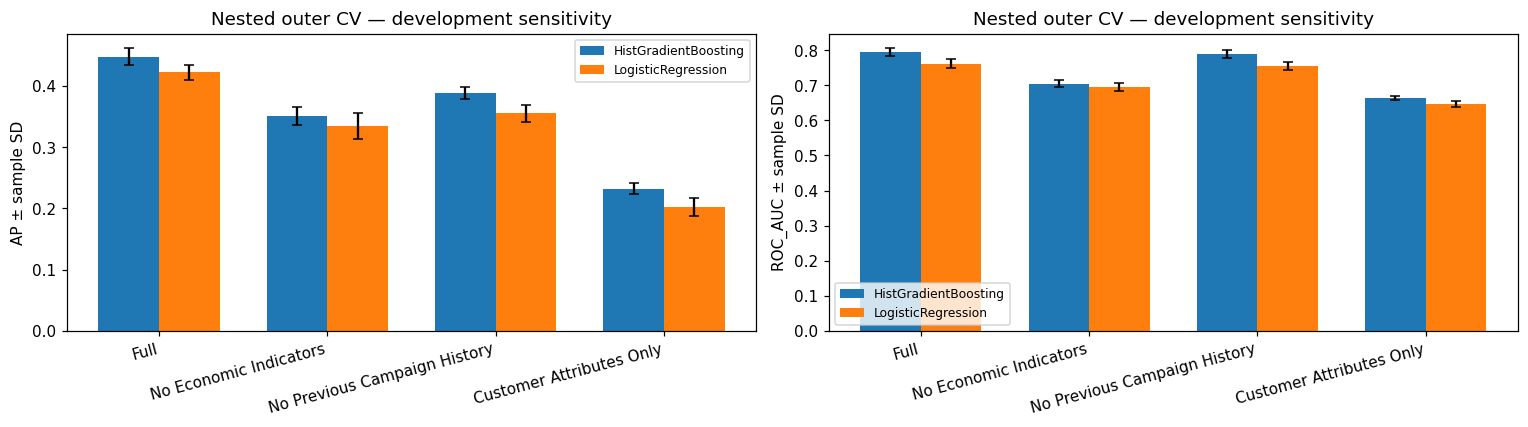

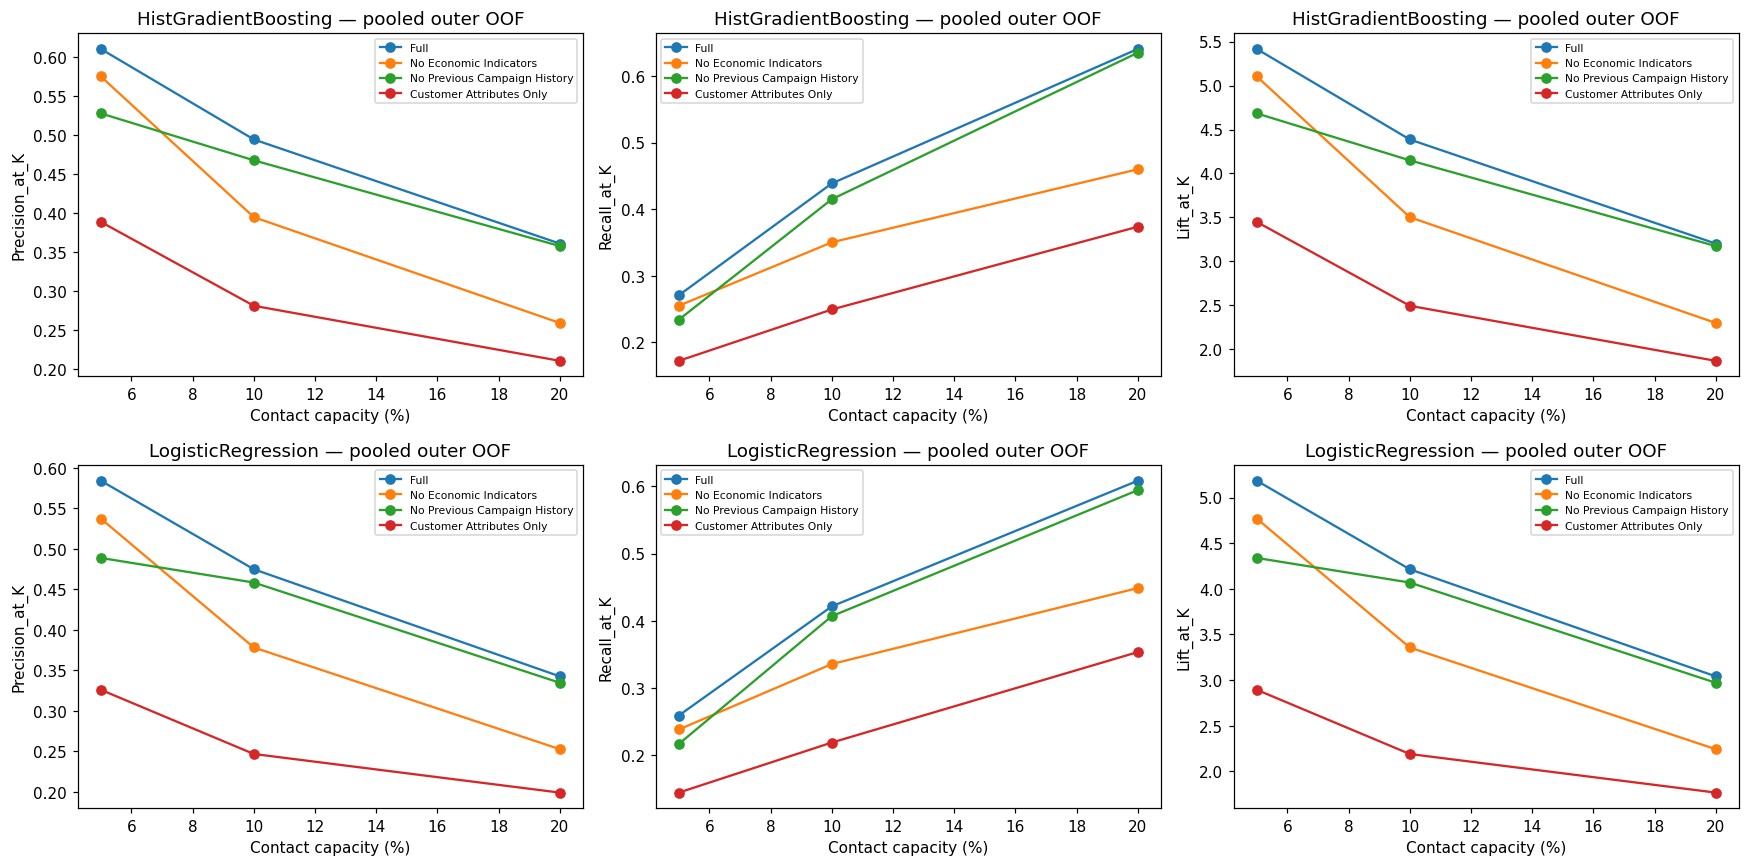

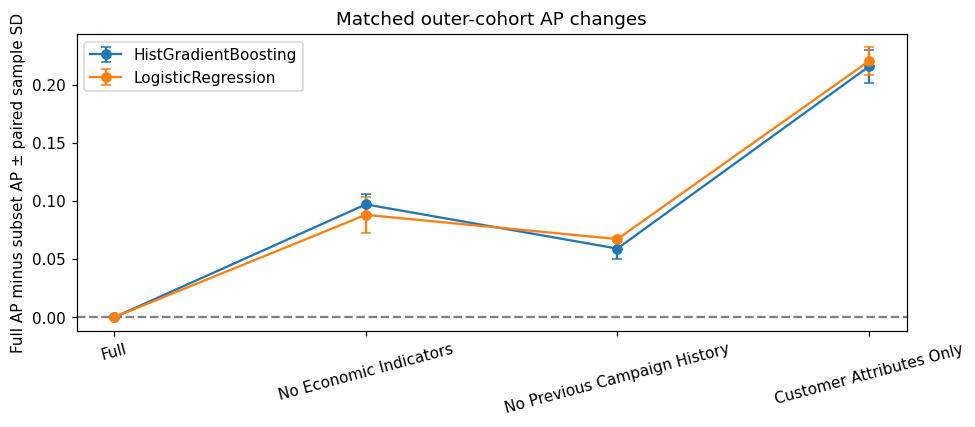

In [5]:
fig,axes=plt.subplots(1,2,figsize=(14,4))
for ax,metric in zip(axes,['AP','ROC_AUC']):
    x=np.arange(len(GROUPS));width=.36
    for i,m in enumerate(MODELS):
        ax.bar(x+(i-.5)*width,[means.loc[(m,g),metric] for g in GROUPS],width,
            yerr=[sds.loc[(m,g),metric] for g in GROUPS],capsize=3,label=m)
    ax.set_xticks(x,list(GROUPS),rotation=15,ha='right');ax.set(ylabel=metric+' ± sample SD',title='Nested outer CV — development sensitivity');ax.legend(fontsize=8)
plt.tight_layout();plt.show()
fig,axes=plt.subplots(2,3,figsize=(16,8))
for i,m in enumerate(MODELS):
    for ax,metric in zip(axes[i],['Precision_at_K','Recall_at_K','Lift_at_K']):
        for g in GROUPS:
            d=pooled.loc[pooled.model.eq(m)&pooled.feature_group.eq(g)]
            ax.plot(d.fraction*100,d[metric],marker='o',label=g)
        ax.set(xlabel='Contact capacity (%)',ylabel=metric,title=m+' — pooled outer OOF');ax.legend(fontsize=7)
plt.tight_layout();plt.show()
fig,ax=plt.subplots(figsize=(9,4))
for m in MODELS:
    d=loss_summary.loc[loss_summary.model.eq(m)].set_index('feature_group').loc[list(GROUPS)]
    ax.errorbar(list(GROUPS),d.AP_loss_mean,yerr=d.AP_loss_sample_SD,marker='o',capsize=3,label=m)
ax.axhline(0,color='gray',ls='--');ax.set(ylabel='Full AP minus subset AP ± paired sample SD',title='Matched outer-cohort AP changes');ax.tick_params(axis='x',rotation=15);ax.legend()
plt.tight_layout();plt.show()



## 6. Audit, source preservation and interpretation

Recheck hashes and original development snapshot; run existing preprocessing tests if supplied. All 1,940 fresh fits/probability calls must pass. Review compute cost, every selected configuration, candidate AP scores, fold manifest, training-only recency/scaling statistics and warnings. The final summary separates observed results, evidence-based interpretation and unresolved timing hypotheses.

Economic/history removal reduces dependence on those source requirements but does not prove remaining customer fields were available at campaign start. All remaining predictors are Provisional. Missing customer IDs/timestamps, publication vintages, prior full-data EDA and development-driven model exploration remain unresolved. No held-out access, final selection, Phase 6B, commit or push. Approve next-phase feature contract, shortlist and decision objective separately.


In [6]:
for name,digest in input_hashes.items():assert sha(PROJECT_DIR/name)==digest,name+' changed'
pd.testing.assert_frame_equal(dev,snapshot,check_exact=True)
assert all(a['status']=='PASS' for a in FIT_AUDIT+PRED_AUDIT)
for t in [outer_results,pooled,local,local_summary,loss_summary,cost_summary]:assert np.isfinite(t.select_dtypes('number').to_numpy()).all()
# Existing approved synthetic tests are optional uploads in Colab, mandatory when present.
import subprocess
if (PROJECT_DIR/'tests/test_preprocessing.py').is_file():
    result=subprocess.run([sys.executable,'-m','unittest','discover','-s','tests','-v'],cwd=PROJECT_DIR,capture_output=True,text=True)
    test_log=result.stdout+result.stderr;assert result.returncode==0,test_log
    unit_test_status='PASS — all 4 existing preprocessing tests'
else:
    test_log='Existing tests/test_preprocessing.py not uploaded; run the repository tests separately.'
    unit_test_status='Not run in this runtime: test file not uploaded'
print(test_log)
print('PASS: 1,940 fresh complete fits and 1,940 authorized probability calls; sources/split unchanged; no held-out use.')
def mdtable(frame,index=False):
    t=frame.reset_index() if index else frame.copy()
    def fmt(v):return f'{v:.6f}' if isinstance(v,(float,np.floating)) else str(v).replace('|',' / ').replace('\n',' ')
    return '\n'.join(['| '+' | '.join(map(str,t.columns))+' |','| '+' | '.join(['---']*len(t.columns))+' |']+['| '+' | '.join(fmt(v) for v in r)+' |' for r in t.itertuples(index=False,name=None)])
elapsed=time.perf_counter()-started_all
warnings_text=mdtable(pd.DataFrame(WARNING_LOG)) if WARNING_LOG else 'None recorded during all 1,940 experiment fits.'
observations=[]
for m in MODELS:
    full=means.loc[(m,'Full')];parts=[]
    for g in list(GROUPS)[1:]:
        v=means.loc[(m,g)];loss=full.AP-v.AP
        captures=pooled.loc[pooled.model.eq(m)&pooled.feature_group.eq(g)].sort_values('fraction')
        parts.append(f"{g}: AP {v.AP:.6f} (full-minus-subset {loss:+.6f}); ROC-AUC {v.ROC_AUC:.6f}; pooled captured subscribers at 5/10/20% = "+' / '.join(map(str,captures.captured_subscribers))+'.')
    observations.append(f"**{m}** full AP {full.AP:.6f}, ROC-AUC {full.ROC_AUC:.6f}. "+' '.join(parts))
observed_text='\n\n'.join(observations)
summary=f"""# Phase 6A — Feature availability and ablation study

## Scope, source and prespecified experiments

Started from latest fetched/merged main **{BASE_MAIN_COMMIT}** (Phase 5B-2 merge included); current feature branch fast-forwarded to it without a new commit. Reviewed README, project planning DOCX and Phase 2C–5B-2 notebooks/summaries/preprocessing/split. Original HGB and LR only, class_weight=None. No resampling, new features, new grids, threshold optimization, final model/policy selection, held-out evaluation or Phase 6B.

This is **development-only sensitivity analysis**, not independent validation of model families, grids or feature concerns identified after prior development exploration. Groups were specified by the user before this experiment, not selected from outer outcomes. All remaining fields stay Provisional. Ablation measures predictive dependence under this validation design, not causality, feature availability or safety.

## Exact feature groups and ordering

{mdtable(feature_table)}

Input order filters the approved FEATURES sequence; it is not alphabetically reordered. Transformer output order remains approved categorical blocks, selected NUMERICAL order, then [recency_days, recency_available] only when included. Every group keeps all six categorical fields; quantitative counts are 7 / 2 / 6 / 1. Recency is either a complete two-column component or completely removed, with no zero-filled stand-ins for excluded predictors.

## Data integrity, row order and validation design

Cleaned SHA-256 `{input_hashes['02_cleaned_dataset.csv']}` equals the saved split manifest hash before positions are applied. Unique/disjoint/exhaustive saved indices: 32,940 development / 8,236 held-out; unchanged assignment and row order. CSV parser skips held-out rows; only development features/labels are materialized, restored to saved development-index order. The original raw CSV, if present, is only byte-hashed. No held-out feature/label fitting, profiling or evaluation here.

Outer StratifiedKFold(n_splits=5, shuffle=True, random_state=42), validation-position SHA-256 `{outer_hash}`, matches Phases 5A/5B. Each validation cohort has 6,588 rows, each outer training set 26,352. Same ordered outer/inner folds across all eight procedures. Each outer-training set gets a fresh five-fold GridSearchCV, AP-only model selection, refit='AP', n_jobs=1, error_score='raise'. Selected complete pipelines refit only outer-training rows and predict outer-validation rows once. No complete-development fitting or preprocessing. No reduced-feature set borrows full-feature optimal parameters.

Grids exactly match approved Phase 5A:
- LR C=[0.1,1,10], lbfgs/default L2, max_iter=1000, seed=42, class_weight=None: 3 candidates.
- HGB learning_rate=[0.05,0.1], max_iter=[100,200], max_leaf_nodes=[15,31], l2_regularization=[0,1], early_stopping=False, categorical_features=None, seed=42, class_weight=None: 16 candidates.

C controls LR inverse regularization; HGB learning rate and iteration count control boosting updates/budget, leaf count controls tree complexity, L2 regularizes leaf predictions. Every feature set has equal search budget within each family. All grids rerun freshly, including Full: **1,900 candidate-fold fits +40 selected outer-training refits =1,940 fits**. No outer-score-driven grid changes. Full metrics and selected parameters reproduce Phase 5A at reported precision.

Classification threshold is fixed at positive probability >=0.50, used only as a reference. Precision/recall/F1 use zero_division=0. AP is Average Precision, not trapezoidal PR area. SDs use sample ddof=1 across five outer folds; these folds share training observations and are not independent confidence intervals. Inner scores/candidate rankings below are selection data, not independent performance estimates.

## Experiment-specific adapter and equivalence

preprocessing.py has no subset argument, so a small notebook-only adapter obtains a fresh approved factory Pipeline, filters each unfitted ColumnTransformer column list to the prespecified group, and removes empty transformer entries. Approved transformer objects/behavior are reused rather than reimplemented. Original factory/module remain unchanged and subsequent calls still have full original columns. Excluded features are not passed to estimator fitting or prediction and are not filled with constants.

Full-feature adapter versus original factory: identical transformed arrays, feature names, categories and fitted ordinary/conditional statistics on a 300-fit/100-transform fixture drawn solely from outer fold 1 training rows. Synthetic unseen job in the validation fixture confirms all-zero unknown-level block without changing source rows. Every group/model is cloneable and finite; absent recency means no recency transformer or output names. Fixture tests do not fit any predictive model or full-development transformer.

{mdtable(pd.DataFrame(adapter_checks))}

OHE retains drop=None, handle_unknown='ignore', dense float64 indicators, six training-only vocabularies. LR StandardScaler uses only selected quantitative fitting columns; ConditionalRecencyScaler, when present, uses only available-recency fitting observations with approved fallback behavior, unavailable transformed days=0 and indicator unscaled. HGB numeric/recency values pass through unchanged; dummy indicators are numeric, native categorical handling off. A stateless guard checks values and returns them unchanged. No global encoded/scaled matrix.

## Individual outer-validation predictive results

{mdtable(outer_results)}

## Mean and sample SD of outer metrics

{mdtable(comparison,index=True)}

## Paired full-minus-subset losses and model rankings

Positive loss means reduced AP/ROC-AUC after removal; negative means an observed gain. These are matched validation-fold differences, not significance tests.

{mdtable(paired)}

{mdtable(loss_summary)}

{mdtable(model_order)}

## Observed findings

{observed_text}

Interpret these group-level differences alongside fold spread, not just the best mean. Exclusion/refitting changes available information and the optimal permitted configuration; differences do not isolate an individual feature's importance, prove economic/history causal effects, or establish that any variable is unavailable. The groups may share information and interact; their losses need not add. AP/ROC-AUC and equal-capacity capture measure ranking changes. Precision/recall/F1 at .50 can additionally change with probability scale/calibration; they do not establish the best deployment decision rule.

## Business targeting — fold-local results

Ranking uses untouched outer-validation probabilities. K=ceil(fraction*N), descending score then cleaned-file row position for outcome-independent deterministic ties. Precision@K=captured/K; Recall@K=captured/cohort positives; Lift@K=precision/cohort prevalence. Every model/group gets identical K within the same cohort. Capture refers to historical subscribers, not the causal effect of contacting them.

{mdtable(local)}

Mean/sample SD across five validation cohorts:

{mdtable(local_summary)}

## Pooled OOF targeting diagnostics

{mdtable(pooled)}

Pooled capacities are 1,647 / 3,294 / 6,588; per-fold capacities are 330 / 659 / 1,318, so summed fold-local capacities are 1,650 / 3,295 / 6,590. Pooled scores come from five separately fitted/calibrated models and are descriptive diagnostics, not a single deployable model's independent test performance. Fold-local rankings reduce sensitivity to cross-fold score calibration. No capacity, call cost, incremental response or financial value was supplied. Lift is predictive concentration, not causal campaign uplift.

## Inner-selected hyperparameters and search evidence

{mdtable(selections)}

Every candidate's inner AP (model-selection estimates only):

{mdtable(candidates)}

## Computational cost

{mdtable(cost)}

{mdtable(cost_summary)}

Elapsed through experiments, figures and tests: {elapsed:.2f}s. Versions: sklearn {sklearn.__version__}, pandas {pd.__version__}, NumPy {np.__version__}. GridSearchCV/native threads limited to one. No reduction/expansion of approved grids. Colab instructions are in the executed notebook; local Python execution is verified, hosted Colab was not directly exercised. Previous grids/results were preserved.

## Technical leakage and reproducibility audit

All 1,940 fresh complete pipeline fits and 1,940 probability calls passed partition assertions. Every fit uses exactly an authorized inner-training partition or outer-training refit, never all development; all fitting/prediction rows exclude held-out indices. Validation prediction rows are disjoint from their estimator's fitting rows, with exact authorized cohort identity. Threshold stays .50. No outer-label feature/hyperparameter/threshold selection.

Every OHE category vocabulary matches its fitting rows. LR ordinary mean/variance/scale/sample count equals fitting-only selected numerical data. Available-only conditional statistics match fitting observations; unavailable days remain zero and availability remains unscaled on validation. History-free configurations have no recency component or names. HGB selected numerical/recency outputs equal the raw subset values exactly. Validation transformation signatures stay fixed. Finite representations/probabilities/metrics, [0,1] class order, seeds, no weighting/resampling, full-feature original equivalence and original CV replication all passed. Source hashes and development snapshot unchanged after execution; separate final Git checks compare all pre-existing tracked artifacts against approved main byte-for-byte.

{mdtable(fit_summary)}

Selected refit statistics (inner candidate fits are also audited above):

{mdtable(refit_audit)}

Inner-fold manifest, identical across models/groups:

{mdtable(pd.DataFrame(inner_manifest))}

Existing preprocessing tests: **{unit_test_status}**.

```text
{test_log.strip()}
```

Warnings during model fitting:

{warnings_text}

## Feature availability: facts, hypotheses and unresolved assumptions

**Observed documentation facts:** README describes economic indicators with quarterly/monthly/daily frequencies and history as prior-campaign information, but provides no observation/publication/revision timestamps or campaign-start as-of snapshots. The project planning DOCX asks about economic value, preprocessing and appropriate held-out/CV use; its approximate pre-cleaning split counts differ from the approved post-cleaning saved assignment. Prior approved exclusions (duration, campaign, contact, month, day_of_week and original pdays) remain excluded. The original 999 recency sentinel is not reintroduced.

**Evidence-based interpretation:** dropping economic indicators reduces reliance on shared economic-period information and publication-vintage joins. Dropping history removes dependence on prior-contact cutoff/reference-date definitions. Customer attributes only removes both sources and is a useful conservative information-requirement comparison, at the observed predictive cost. Removing those dependencies can make a proposed information requirement easier to defend; it does not certify pre-campaign availability of the remaining fields.

**Hypotheses, not established facts:** economic values might proxy campaign period or later information; contact history might be updated after campaign start; remaining customer/financial status might be retrospectively recorded. Ablation alone cannot decide whether these explanations cause a performance difference. Confirm customer-record effective dates, history cutoff and recency reference date, economic publication vintages/as-of joins and outcome window with the data owner. Customer-only fields (age/job/marital/education/default/housing/loan) all remain Provisional. All other retained fields are Provisional in groups where present.

Missing customer IDs and dates prevent grouped-client/forward-time validation and allow repeated-client or temporal context overlap across random folds. Prior whole-dataset EDA and development-driven model/grid exploration remain limitations. Random stratified nesting prevents this experiment's direct preprocessing/selection leakage, not every kind of leakage or future-campaign risk. No unseen-client/future-period generalization or independent final performance is established.

## Recommendations for Phase 6B discussion — not executed

Use the observed AP/ROC-AUC and equal-capacity capture losses to discuss the cost of information requirements. Retain full original HGB and original LR as references and consider the prespecified reduced-feature counterparts where their required inputs can be verified; do not automatically retain a full feature just because it raises AP. Do not choose final model, subset or policy from a single best outer mean. The four subsets are sensitivity scenarios, not proof of feature timing or new approved deployment schemas.

Team approval is needed for an acceptable campaign-start feature contract, feasible model/subset shortlist, contact capacity and decision objective, treatment of unresolved timestamps/IDs, and a prespecified final development-only model/policy-selection procedure before any one-time held-out evaluation. No threshold search, final policy, Phase 6B, commit or push has been performed. Deliverables: 09_feature_ablation.ipynb and 09_feature_ablation_summary.md in the repository, pending review.
"""
_review_rows=[]
for _g in GROUPS:
    _review_rows.append({'feature_group':_g,'predictors':len(GROUPS[_g]),
        'HGB AP mean ± sample SD':f"{means.loc[('HistGradientBoosting',_g),'AP']:.6f} ± {sds.loc[('HistGradientBoosting',_g),'AP']:.6f}",
        'LR AP mean ± sample SD':f"{means.loc[('LogisticRegression',_g),'AP']:.6f} ± {sds.loc[('LogisticRegression',_g),'AP']:.6f}"})
_capture_lines=[]
for _g in GROUPS:
    _d=pooled.loc[pooled.model.eq('HistGradientBoosting')&pooled.feature_group.eq(_g)].sort_values('fraction')
    _capture_lines.append('- '+_g+': '+' / '.join(str(int(v)) for v in _d.captured_subscribers)+' historical subscribers.')
_hgb_full=means.loc[('HistGradientBoosting','Full'),'AP']
_hgb_losses={_g:_hgb_full-means.loc[('HistGradientBoosting',_g),'AP'] for _g in list(GROUPS)[1:]}
_ranking_note='HGB has higher mean AP than LR in all four feature groups.' if all(means.loc[('HistGradientBoosting',g),'AP']>means.loc[('LogisticRegression',g),'AP'] for g in GROUPS) else 'Mean model rankings vary across feature groups; consult the model-ranking table.'
completion_review=f"""## Completion review

{mdtable(pd.DataFrame(_review_rows))}

HGB full-minus-subset mean AP losses: no economics {_hgb_losses['No Economic Indicators']:.6f}; no history {_hgb_losses['No Previous Campaign History']:.6f}; customer-only {_hgb_losses['Customer Attributes Only']:.6f}. {_ranking_note} This is a descriptive development comparison, not a significance test or final selection.

At identical pooled contact capacities of 1,647 / 3,294 / 6,588 (5% / 10% / 20%), HGB captures:

{chr(10).join(_capture_lines)}

Removing economic context or history therefore has a measurable predictive cost in this experiment. The two group losses cannot be added to infer the combined loss. ROC-AUC, AP, fixed-.50 results and fold-local targeting below should be read together; lower .50 recall alone is not proof of poor ranking or a basis for new threshold tuning.

**Conditional shortlist for Phase 6B discussion:** keep original full HGB as a research reference and the reduced HGB variants corresponding to whichever feature contract the team can verify. Retain original LR as a simpler benchmark. If economic availability cannot be verified but history can, discuss No Economic Indicators; if history cannot be verified but economic as-of values can, discuss No Previous Campaign History; if neither can, use Customer Attributes Only as the information-restricted comparison, with its observed performance loss. None is certified deployable, including customer-only. Do not select a final subset solely from the largest outer score. These conclusions concern the tested unweighted grids and do not extrapolate imbalance-treatment findings to untested reduced-feature variants.

Source SHA-256 evidence (whole-file integrity checks, not held-out feature/label analysis):

{mdtable(pd.DataFrame([{'artifact':name,'sha256':input_hashes[name]} for name in ['dataset.csv','02_cleaned_dataset.csv','03_split_indices.json','preprocessing.py'] if name in input_hashes]))}

Reported runtime includes audit, search and refit overhead; it is not a hardware-independent algorithm speed benchmark. All predictors in every group remain Provisional. Approve campaign-start source snapshots/as-of rules and a development-only final model/policy-selection plan before Phase 6B; no held-out evaluation or final decision is made here.

"""
completion_review += "At top 5%, HGB without economics captures 947 subscribers versus 869 without history, despite lower overall AP. At top 20%, HGB without history captures 2,356 versus full's 2,377, while no-economics captures 1,707. Thus the relative value of the groups depends on contact capacity; the overall AP order does not settle every Top-K comparison. These remain historical out-of-sample associations, not causal outreach effects.\n\nCustomer-only LR predicts no subscribers at .50 in any fold: precision/recall/F1=0 and accuracy 0.887341. Its AP is nevertheless 0.202251, above development prevalence 0.112659. Customer-only HGB also has low .50 recall (0.021287). This illustrates why fixed-threshold outcomes and ranking metrics must be distinguished; no new threshold was selected.\n\nSeparate final local checks passed: notebook nbformat schema, six executed code cells and syntax, three figures; independently recomputed all 40 outer-fold metric records plus 120 fold-local and 24 pooled Top-K records; all pre-existing tracked artifacts match approved HEAD byte-for-byte. Model warnings: zero. Four approved preprocessing tests pass. Hosted Colab execution was not directly tested.\n\n"
_title,_rest=summary.split('\n',1)
summary=_title+'\n\n'+completion_review+_rest.lstrip('\n')

(PROJECT_DIR/'09_feature_ablation_summary.md').write_text(summary)
print('Saved Phase 6A summary. No commit/push, held-out evaluation or Phase 6B.')


test_factory_is_unfitted_and_cloneable (test_preprocessing.ConditionalRecencyTests.test_factory_is_unfitted_and_cloneable) ... ok
test_invalid_input_and_unfitted (test_preprocessing.ConditionalRecencyTests.test_invalid_input_and_unfitted) ... ok
test_observed_only_and_no_refit (test_preprocessing.ConditionalRecencyTests.test_observed_only_and_no_refit) ... ok
test_safe_fallbacks (test_preprocessing.ConditionalRecencyTests.test_safe_fallbacks) ... ok

----------------------------------------------------------------------
Ran 4 tests in 0.021s

OK

PASS: 1,940 fresh complete fits and 1,940 authorized probability calls; sources/split unchanged; no held-out use.
Saved Phase 6A summary. No commit/push, held-out evaluation or Phase 6B.


## Completion review

| feature_group | predictors | HGB AP mean ± sample SD | LR AP mean ± sample SD |
| --- | --- | --- | --- |
| Full | 15 | 0.448145 ± 0.014219 | 0.422429 ± 0.011606 |
| No Economic Indicators | 10 | 0.351146 ± 0.015153 | 0.334394 ± 0.021340 |
| No Previous Campaign History | 12 | 0.389129 ± 0.009401 | 0.355256 ± 0.013265 |
| Customer Attributes Only | 7 | 0.232569 ± 0.009506 | 0.202251 ± 0.015223 |

HGB full-minus-subset mean AP losses: no economics 0.096999; no history 0.059017; customer-only 0.215576. HGB has higher mean AP than LR in all four feature groups. This is a descriptive development comparison, not a significance test or final selection.

At identical pooled contact capacities of 1,647 / 3,294 / 6,588 (5% / 10% / 20%), HGB captures:

- Full: 1005 / 1628 / 2377 historical subscribers.
- No Economic Indicators: 947 / 1300 / 1707 historical subscribers.
- No Previous Campaign History: 869 / 1540 / 2356 historical subscribers.
- Customer Attributes Only: 640 / 926 / 1387 historical subscribers.

Removing economic context or history therefore has a measurable predictive cost in this experiment. The two group losses cannot be added to infer the combined loss. ROC-AUC, AP, fixed-.50 results and fold-local targeting below should be read together; lower .50 recall alone is not proof of poor ranking or a basis for new threshold tuning.

**Conditional shortlist for Phase 6B discussion:** keep original full HGB as a research reference and the reduced HGB variants corresponding to whichever feature contract the team can verify. Retain original LR as a simpler benchmark. If economic availability cannot be verified but history can, discuss No Economic Indicators; if history cannot be verified but economic as-of values can, discuss No Previous Campaign History; if neither can, use Customer Attributes Only as the information-restricted comparison, with its observed performance loss. None is certified deployable, including customer-only. Do not select a final subset solely from the largest outer score. These conclusions concern the tested unweighted grids and do not extrapolate imbalance-treatment findings to untested reduced-feature variants.

Source SHA-256 evidence (whole-file integrity checks, not held-out feature/label analysis):

| artifact | sha256 |
| --- | --- |
| dataset.csv | 81fd5eb4b659dddbc704edd90376c32714c3f6a43b887cb686762903bc793f0d |
| 02_cleaned_dataset.csv | c1a19ca755279a5f22ba22e06b8d5ca22797d9b6351c69fe4cfafd2b47041d49 |
| 03_split_indices.json | 397e6e9c66ba3b6b5f6bef6232e00dc392c9ae9d77fdfda28a2d7dc02693596b |
| preprocessing.py | 3959b4db9a561be5bf7373dfcf82ab85c24a288250e26180599a403b7e551ed8 |

Reported runtime includes audit, search and refit overhead; it is not a hardware-independent algorithm speed benchmark. All predictors in every group remain Provisional. Approve campaign-start source snapshots/as-of rules and a development-only final model/policy-selection plan before Phase 6B; no held-out evaluation or final decision is made here.

At top 5%, HGB without economics captures 947 subscribers versus 869 without history, despite lower overall AP. At top 20%, HGB without history captures 2,356 versus full's 2,377, while no-economics captures 1,707. Thus the relative value of the groups depends on contact capacity; the overall AP order does not settle every Top-K comparison. These remain historical out-of-sample associations, not causal outreach effects.

Customer-only LR predicts no subscribers at .50 in any fold: precision/recall/F1=0 and accuracy 0.887341. Its AP is nevertheless 0.202251, above development prevalence 0.112659. Customer-only HGB also has low .50 recall (0.021287). This illustrates why fixed-threshold outcomes and ranking metrics must be distinguished; no new threshold was selected.

Separate final local checks passed: notebook nbformat schema, six executed code cells and syntax, three figures; independently recomputed all 40 outer-fold metric records plus 120 fold-local and 24 pooled Top-K records; all pre-existing tracked artifacts match approved HEAD byte-for-byte. Model warnings: zero. Four approved preprocessing tests pass. Hosted Colab execution was not directly tested.

